## Imports

In [2]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import random
import math
%matplotlib inline

In [3]:
names = open('names.txt', 'r').read().splitlines()
names = [name.strip() for name in names]
len(names)

133939

##### idx to char and vice versa map

In [4]:
vocab = sorted(set(list(''.join(names))))
# --- char to idx map ---
char_to_idx = { char:idx + 1 for idx, char in enumerate(vocab[2:])}
char_to_idx.update({'.': 0, '-': 27, ' ': 28})
# --- idx to char map ---
idx_to_char = {idx:char for char,idx in char_to_idx.items()}
vocab_size = len(idx_to_char)

##### dataset creation and splitting

In [5]:
context_length = 3

def build_dataset(names, context_length = 3):
    random.seed(42)
    X, Y = [], []

    for name in names:
        context = [0] * context_length
        for ch in name + '.':
            X.append(context)
            idx = char_to_idx[ch]
            Y.append(idx)
            context = context[1:] + [idx]

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y

def train_split_dataset(names, X, Y, seed = 42):
    random.seed(seed)
    random.shuffle(names)
    n1 = int(0.8 * len(names))
    n2 = int(0.9 * len(names))
    X_tr, Y_tr = X[:n1], Y[:n1]
    X_test, Y_test = X[n1:n2], Y[n1:n2]
    X_dev, Y_dev = X[n2:], Y[n2:]

    return (X_tr, Y_tr), (X_test, Y_test), (X_dev, Y_dev)

In [6]:
X, Y = build_dataset(names)
X_tr, Y_tr = train_split_dataset(names, X, Y)[0]
X_test, Y_test = train_split_dataset(names, X, Y)[1]
X_dev, Y_dev = train_split_dataset(names, X, Y)[2]

In [7]:
tr_size = X_tr.shape[0]

##### building the network

In [333]:
n_emb = 2
n_hidden = 120

gen = torch.Generator().manual_seed(125)
C = torch.randn((vocab_size, n_emb), generator=gen)
emb = C[X]
# --- tanh layer ---
w1 = torch.randn((n_emb * context_length, n_hidden), generator=gen) * (5/3 / (n_emb * context_length)**0.5)
# --- softmax layer ---
w2 = torch.randn((n_hidden, vocab_size), generator=gen) * 0.01
b2 = torch.randn((vocab_size), generator=gen) * 0
# --- batch norm layer ---
bn_gain = torch.ones((1, n_hidden))
bn_bias = torch.zeros((1, n_hidden))
bn_mean_running = torch.zeros((1, n_hidden))
bn_std_running = torch.zeros((1, n_hidden))

parameters = [C, w1, w2, b2, bn_gain, bn_bias]
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True

4527


##### training the neural network

In [334]:
epochs, nbatch, batch_ix = 60, 32, 0
steps_per_epoch = math.ceil(tr_size / nbatch)
max_steps = epochs * steps_per_epoch
first_decay_step = max_steps // 2
batch = torch.randperm(tr_size)
loss_i = []

for step in range(max_steps):

    # minibatch construction
    if batch_ix + nbatch > tr_size:
        batch = torch.randperm(tr_size)
        batch_ix = 0
    batches_ix = batch[batch_ix: batch_ix + nbatch]
    Xb, Yb = X_tr[batches_ix], Y_tr[batches_ix]
    batch_ix += nbatch

    # forward pass
    emb = C[Xb]
    emb_cat = emb.view(emb.shape[0], -1)
    # linear layer
    h_preact = emb_cat @ w1
    # --- batch norm layer ---
    bn_meani = h_preact.mean(0, keepdim=True)
    bn_stdi = h_preact.std(0, keepdim=True)
    h_preact = bn_gain * (h_preact - bn_meani) / bn_stdi + bn_bias
    with torch.no_grad():
        bn_mean_running = 0.999 * bn_mean_running + 0.001 * bn_meani
        bn_std_running = 0.999 * bn_std_running + 0.001 * bn_stdi
    # ------------------------
    # non linear layer
    h = torch.tanh(h_preact)
    logits = h @ w2 + b2
    loss = F.cross_entropy(logits, Yb)

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 10**(-0.8) if step < first_decay_step else 10**(-1.8)
    for p in parameters:
        p.data += -lr * p.grad

    # track progress
    if step % steps_per_epoch == 0 or step == max_steps:
        print(f'{step:7d}/ {max_steps:7d}: {loss.item():.4f}')
    loss_i.append(loss.log10().item())

      0/  200940: 3.3669
   3349/  200940: 2.3960
   6698/  200940: 2.2174
  10047/  200940: 2.2474
  13396/  200940: 2.4024
  16745/  200940: 2.4030
  20094/  200940: 2.1756
  23443/  200940: 2.6751
  26792/  200940: 2.3490
  30141/  200940: 2.3728
  33490/  200940: 1.9444
  36839/  200940: 2.2161
  40188/  200940: 2.1388
  43537/  200940: 2.2697
  46886/  200940: 2.3660
  50235/  200940: 2.7690
  53584/  200940: 2.0069
  56933/  200940: 2.7381
  60282/  200940: 2.3333
  63631/  200940: 2.3627
  66980/  200940: 2.5402
  70329/  200940: 2.7263
  73678/  200940: 2.1684
  77027/  200940: 2.3276
  80376/  200940: 2.1802
  83725/  200940: 2.2573
  87074/  200940: 2.2525
  90423/  200940: 2.5572
  93772/  200940: 2.3699
  97121/  200940: 2.2611
 100470/  200940: 2.4897
 103819/  200940: 2.3052
 107168/  200940: 2.2971
 110517/  200940: 2.1799
 113866/  200940: 2.1173
 117215/  200940: 2.2592
 120564/  200940: 2.6729
 123913/  200940: 2.2897
 127262/  200940: 2.0526
 130611/  200940: 2.4125


In [335]:
@torch.no_grad()
def split_loss(split):
  x,y = {
    'train': (X_tr, Y_tr),
    'val': (X_dev, Y_dev),
    'test': (X_test, Y_test),
  }[split]
  emb = C[x]
  embcat = emb.view(emb.shape[0], -1)
  h_preact = embcat @ w1
  h_preact = bn_gain * (h_preact - bn_mean_running) / bn_std_running + bn_bias
  h = torch.tanh(h_preact)
  logits = h @ w2 + b2
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.181046485900879
val 2.315897226333618


#####  inference

In [544]:
index = 0
output_name = ""
g = torch.Generator().manual_seed(1965)
for _ in range(10):
    output_name = ""
    context = [0] * 3
    while True:
        emb = C[torch.tensor([context])]
        h = torch.tanh(emb.view(1, -1) @ w1)
        logits = h @ w2 + b2
        probs = F.softmax(logits, dim=1)
        index = torch.multinomial(probs, num_samples=1, generator=g).item()
        context = context[1:] + [index]
        output_name += idx_to_char[index]
        if index == 0:
            break
    print(output_name[1:-1])

kikik
kiyuzoshunch
keiki
chi
ziylac
kat
kerlo
kikaikikikikikai
kiya
ius kiyu


#### Pytorchifying

In [53]:
class Linear:

    def __init__(self, in_feat, out_feat, bias=False):
        self.weights = torch.randn((in_feat, out_feat), generator=g) / (in_feat)**0.5
        self.bias = torch.zeros(out_feat) if bias else None

    def __call__(self, x):
        output = x @ self.weights
        self.out = output if self.bias is None else output + self.bias
        return self.out

    def parameters(self):
        return [self.weights] + ([] if self.bias is None else [self.bias])

class BatchNorm1d:

    def __init__(self, num_features, eps=1e-05, momentum=0.1):
        self.eps = eps
        self.momentum = momentum
        self.training = True
        self.gamma = torch.ones(num_features)
        self.beta = torch.zeros(num_features)
        self.mean_running = torch.zeros(num_features)
        self.var_running = torch.ones(num_features)

    def __call__(self, x):
        if self.training:
            xmean = x.mean(0, keepdim=True)
            xvar = x.var(0, keepdim=True)
        else:
            xmean = self.mean_running
            xvar = self.var_running

        xhat = (x - xmean) / (torch.sqrt(xvar + self.eps))
        self.out = self.gamma * xhat + self.beta
        if self.training:
            with torch.no_grad():
                self.mean_running = self.momentum * self.mean_running + (1 - self.momentum) * xmean
                self.var_running = self.momentum * self.var_running + (1 - self.momentum) * xvar

        return self.out

    def parameters(self):
        return [self.gamma, self.beta]

class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out
    def parameters(self):
        return []

In [65]:
n_emb = 2
n_hidden = 120
g = torch.Generator().manual_seed(125)
C = torch.randn((vocab_size, n_emb), generator=g)
layers = [
    Linear(context_length * n_emb, n_hidden), BatchNorm1d(n_hidden), Tanh(),
    Linear(              n_hidden, vocab_size), BatchNorm1d(vocab_size),
]
parameters = [C] + [p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True

4556


In [67]:
batch, batch_ix, batch_size = torch.randperm(tr_size), 0, 32
steps_per_batch = math.ceil(tr_size / batch_size)
loss_i = []

for step in range(214000):

    # minibatch construction
    if batch_ix + batch_size > tr_size:
        batch = torch.randperm(tr_size)
        batch_ix = 0
    batches_ix = batch[batch_ix: batch_ix + batch_size]
    Xb, Yb = X_tr[batches_ix], Y_tr[batches_ix]
    batch_ix += batch_size

    # forward pass
    emb = C[Xb]
    x = emb.view(emb.shape[0], -1)
    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, Yb)

    # backward pass
    # for layer in layers:
    #     layer.out.retain_grad()
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 10**(-0.8) if step < 150_000 else 10**(-1.8)
    for p in parameters:
        p.data += -lr * p.grad

    # track progress
    if step % steps_per_batch == 0 or step == max_steps:
        print(f'{step:7d}/ {214000:7d}: {loss.item():.4f}')
    loss_i.append(loss.log10().item())

      0/  214000: 2.2132
   3349/  214000: 2.5563
   6698/  214000: 2.3133
  10047/  214000: 2.4064
  13396/  214000: 2.1713
  16745/  214000: 2.0895
  20094/  214000: 2.2799
  23443/  214000: 2.2796
  26792/  214000: 2.7728
  30141/  214000: 2.4320
  33490/  214000: 2.6543
  36839/  214000: 2.2227
  40188/  214000: 2.2164
  43537/  214000: 2.1393
  46886/  214000: 2.5629
  50235/  214000: 2.1488
  53584/  214000: 1.9487
  56933/  214000: 2.0069
  60282/  214000: 2.7084
  63631/  214000: 2.2058
  66980/  214000: 2.0875
  70329/  214000: 1.9964
  73678/  214000: 2.0752
  77027/  214000: 2.3128
  80376/  214000: 2.2672
  83725/  214000: 2.4793
  87074/  214000: 2.1279
  90423/  214000: 1.7866
  93772/  214000: 2.0490
  97121/  214000: 1.9707
 100470/  214000: 2.2091
 103819/  214000: 2.7353
 107168/  214000: 2.0430
 110517/  214000: 2.1675
 113866/  214000: 2.3091
 117215/  214000: 2.0212
 120564/  214000: 2.1484
 123913/  214000: 2.1358
 127262/  214000: 2.4426
 130611/  214000: 2.5675


In [68]:
@torch.no_grad()
def split_loss(split):
    x, y = {
        'train': (X_tr, Y_tr),
        'val': (X_dev, Y_dev),
        'test': (X_test, Y_test),
    }[split]
    emb = C[x]
    x = emb.view(emb.shape[0], -1)
    for layer in layers:
        if isinstance(layer, BatchNorm1d):
            layer.training = False
        x = layer(x)
    loss = F.cross_entropy(x, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.193816661834717
val 2.337876796722412


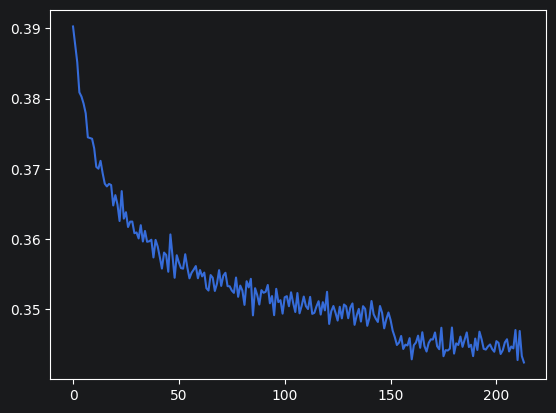

In [80]:
plt.plot(torch.tensor(loss_i).view(-1, 1000).mean(1))

2 layers: train 2.195988416671753, val 2.338879108428955<br>